# Enhanced IRRA — learning to match people and words
**A visual research notebook · CLIP ViT-B/16 · RSTPReid**

Can a description of clothing, colors, and accessories retrieve the right person image? E6 learns a shared representation of photographs and descriptions, with an extra exercise: recover hidden visual phrases by looking at the photo.

**Selected result: 43.15% Rank-1, 61.15% Rank-5, 36.04% mAP.** These are validation results, not held-out test scores.

This notebook is an explanation of the research. Run All reads included evidence and runs small teaching examples; it does not need private model/data files or start an application. Screenshots show recorded model behavior, not fresh inference.

## 1. Open the evidence
Install the project environment using the instructions in the README. Start the notebook from the repository root. Saved outputs are already included for readers who only want to explore the project.

In [1]:
import json
from pathlib import Path
from typing import TypedDict, cast

import matplotlib.pyplot as plt
import pandas as pd
import torch
from IPython.display import Image, display

from enhanced_irra.losses import identity_distribution, sdm_loss
from enhanced_irra.masking import MaskedCaption, mask_caption, tokenizer_connector


class Metrics(TypedDict):
    rank1: float
    rank5: float
    rank10: float
    mAP: float
    mINP: float


class SelectedModel(TypedDict):
    best_epoch: int
    validation: Metrics


class Study(TypedDict):
    selected_model: SelectedModel
    protocol: dict[str, int | bool]


ROOT: Path = Path.cwd().resolve()
if not (ROOT / 'research/results.json').is_file():
    raise FileNotFoundError('Start this notebook from the research repository root.')
study: Study = cast(Study, json.loads((ROOT / 'research/results.json').read_text()))
history: pd.DataFrame = pd.read_csv(ROOT / 'research/e6-training.csv')
extra: pd.DataFrame = pd.read_csv(ROOT / 'research/additional-finetuning.csv')
torch.set_num_threads(2)
print('Included evidence loaded; no model or dataset download required.')

Included evidence loaded; no model or dataset download required.


## 2. The data
RSTPReid contains 20,505 images and two descriptions per image. Training, validation, and test identities are separate. A pixel audit found four training images duplicated in evaluation splits; excluding only those images leaves **18,501 training images and 37,002 caption pairs**. Evaluation records remain unchanged.

In [2]:
display(pd.DataFrame([
    {'split': 'Training after quarantine', 'identities': 3701, 'images': study['protocol']['training_images'], 'descriptions': study['protocol']['training_captions']},
    {'split': 'Validation', 'identities': 200, 'images': 1000, 'descriptions': 2000},
    {'split': 'Test — reserved', 'identities': 200, 'images': 1000, 'descriptions': 2000},
]).set_index('split'))

,identities,images,descriptions
split,,,
Training after quarantine,3701,18501,37002
Validation,200,1000,2000
Test — reserved,200,1000,2000


## 3. The architecture, without the mystery
CLIP supplies two 12-layer encoders: one reads images, the other reads descriptions. Both are fully fine-tuned. Images use 384×128 geometry; image and text global vectors each have 512 dimensions.

During training, a second text pass hides visual phrases. Eight-head cross-attention connects these text tokens to image details, followed by four refinement blocks and a word-prediction head. At retrieval time, the global representations are sufficient; the extra training heads are omitted.

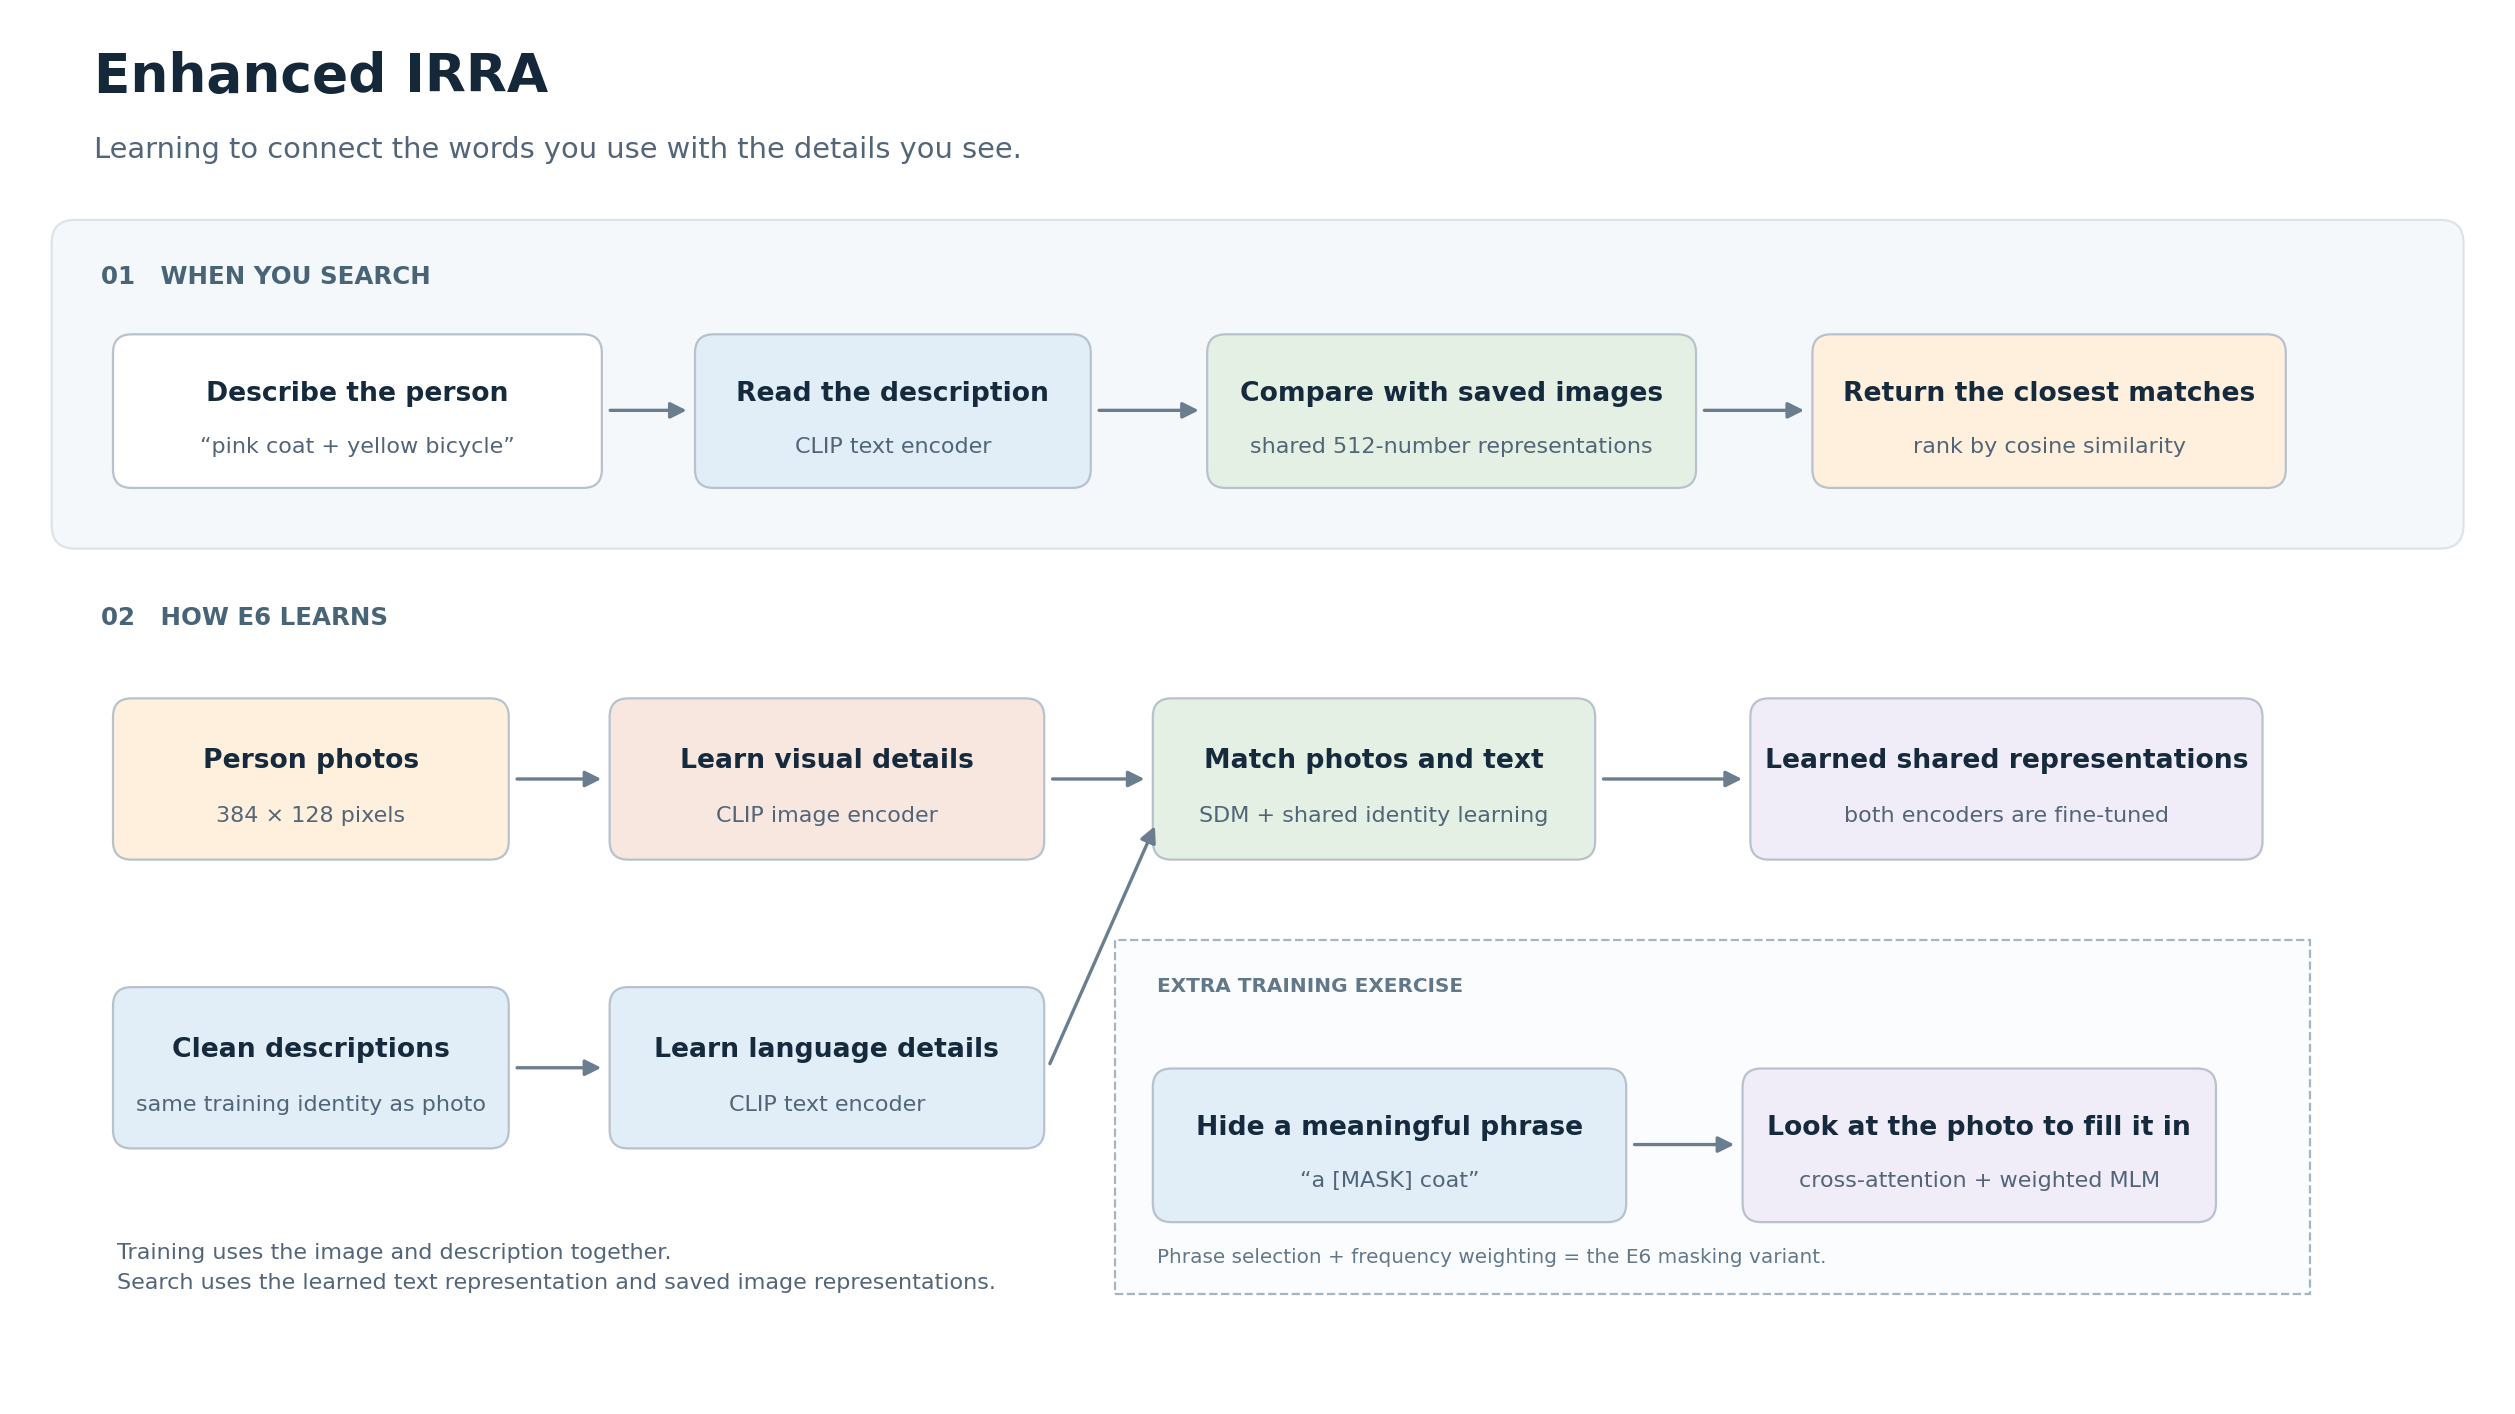

In [3]:
display(Image(filename=str(ROOT / 'assets/architecture.png'), width=1100))

## 4. Three learning signals
$$L=L_{SDM}+L_{ID}+L_{MLM}.$$

- **SDM:** bring matching photo–description distributions together in both directions.
- **Identity learning:** use one shared classifier to distinguish the training identities from either modality.
- **Masked language learning:** use the photo to recover selected original words from corrupted descriptions.

The following is a tiny illustration of SDM, not a trained-model measurement. Matching identity pairs should cost less than mismatched pairs.

In [4]:
identities: torch.Tensor = torch.tensor([0, 1, 2])
features: torch.Tensor = torch.eye(3)
aligned: float = float(sdm_loss(features, features, identities, 0.02))
mismatched: float = float(sdm_loss(features, features.roll(1, dims=0), identities, 0.02))
display(pd.DataFrame({'pairing': ['Aligned identities', 'Mismatched identities'], 'SDM loss': [aligned, mismatched]}))
if aligned >= mismatched:
    raise ValueError('The teaching example did not preserve the expected SDM ordering.')
print('Same-identity target rows sum to:', identity_distribution(identities).sum(1).tolist())

,pairing,SDM loss
0,Aligned identities,-2.436344e-20
1,Mismatched identities,3.684136e+01


Same-identity target rows sum to: [1.0, 1.0, 1.0]


## 5. What makes E6 different?
A fixed visual lexicon detects whole adjective–noun phrases such as *long pink coat*. The selection budget is about 15% of content tokens. Selected tokens are masked 80% of the time, randomly replaced 10%, and left unchanged 10%; all selected positions remain prediction targets. The clean retrieval description stays intact.

E6 also reduces the loss weight of the top 25 frequent training tokens using $\max(0.05,(1-f)^2)$; other tokens keep weight 1. These are selected KPDM-inspired adaptations, not a full reproduction.

In [5]:
tokenizer = tokenizer_connector()
caption: str = 'A woman in a long pink coat carries a small red backpack.'
masked: MaskedCaption = mask_caption(tokenizer.encode(caption), 'phrase', 0.15, 17)
print('Clean description:', caption)
display(pd.DataFrame([
    {'position': position, 'original target': tokenizer.decode([int(masked.targets[position])]), 'corrupted input': tokenizer.decode([int(masked.corrupted[position])])}
    for position in masked.selected
]))
if masked.clean.data_ptr() == masked.corrupted.data_ptr():
    raise ValueError('Clean and corrupted captions must have separate storage.')

Clean description: A woman in a long pink coat carries a small red backpack.


,position,original target,corrupted input
0,10,small,small
1,11,red,<|mask|>
2,12,backpack,<|mask|>


## 6. How training was organized
Original E6: ten epochs, seed 17, batch size 64. Each epoch processes **578 × 64 = 36,992 caption–image pairs**, dropping ten remaining pairs. Images receive random flips, padded crops, random erasing, and CLIP normalization.

AdamW uses peak learning rates **1e-5 for encoders / 5e-5 for heads**, betas (0.9, 0.999), epsilon 1e-8, and weight decay 4e-5 (none for biases/normalization vectors). One warmup epoch precedes cosine decay. BF16, gradient clipping at 1.0, and FP32 probability/loss operations support stability. The highest validation Rank-1 selects the checkpoint.

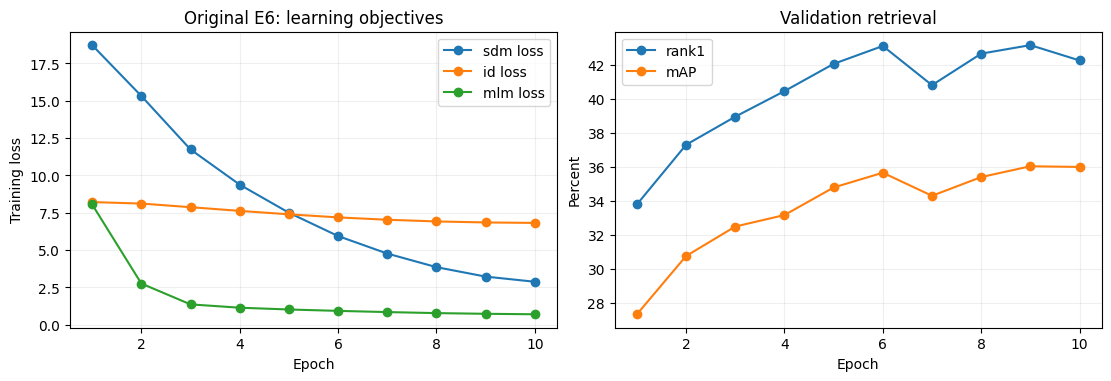

In [6]:
figure, axes = plt.subplots(1, 2, figsize=(11, 3.7), layout='constrained')
for field in ('sdm_loss', 'id_loss', 'mlm_loss'):
    axes[0].plot(history['epoch'], history[field], marker='o', label=field.replace('_', ' '))
for field in ('validation_rank1', 'validation_mAP'):
    axes[1].plot(history['epoch'], history[field], marker='o', label=field.replace('validation_', ''))
axes[0].set(title='Original E6: learning objectives', xlabel='Epoch', ylabel='Training loss')
axes[1].set(title='Validation retrieval', xlabel='Epoch', ylabel='Percent')
for axis in axes:
    axis.legend()
    axis.grid(alpha=0.2)
plt.show()

## 7. Reading the results
Rank-1 asks whether the first image has the correct dataset identity. Rank-5 asks whether a correct identity appears within five images. mAP measures the placement of all relevant images; mINP emphasizes the hardest relevant match. One gallery entry per image, two caption queries per image, and no camera exclusion are used.

The original epoch-9 checkpoint is selected. Its improvement over frozen CLIP does not isolate the contribution of masking. The matched subset pilots used only 256 training identities and a limited step budget; they do not establish superiority of full-data E6.

In [7]:
display(pd.DataFrame([study['selected_model']['validation']]).round(2))
print('Validation: 2,000 descriptions ranked against 1,000 images. Percentages, not test results.')
pilots: pd.DataFrame = pd.read_csv(ROOT / 'research/pilot-comparison.csv')
display(pilots[['experiment', 'rank1_mean', 'mAP_mean']].rename(columns={'rank1_mean': 'Pilot Rank-1 (%)', 'mAP_mean': 'Pilot mAP (%)'}).round(2))

,rank1,rank5,rank10,mAP,mINP,queries,gallery
0,43.15,61.15,68.5,36.04,19.64,2000,1000


Validation: 2,000 descriptions ranked against 1,000 images. Percentages, not test results.


,experiment,Pilot Rank-1 (%),Pilot mAP (%)
0,E1,28.65,23.89
1,E2,27.45,23.46
2,E3,28.35,24.40
3,E4,28.65,23.44
4,E5,28.35,23.34
5,E6,26.95,23.49


## 8. More epochs did not automatically help
A separate fine-tuning stage loaded E6 with fresh AdamW state: peak encoder/head rates 5e-6 / 2.5e-5, two warmup epochs, and a planned 30-epoch cosine schedule. It was stopped after **16 completed epochs** because falling training loss had not produced clear overall validation gains.

Best additional Rank-1: **43.35%** at epoch 2, with slightly lower mAP (**36.00%**). Last completed epoch: **39.45% / 34.13%**. The original E6 remains selected. A new optimization stage is not an exact optimizer-state resume.

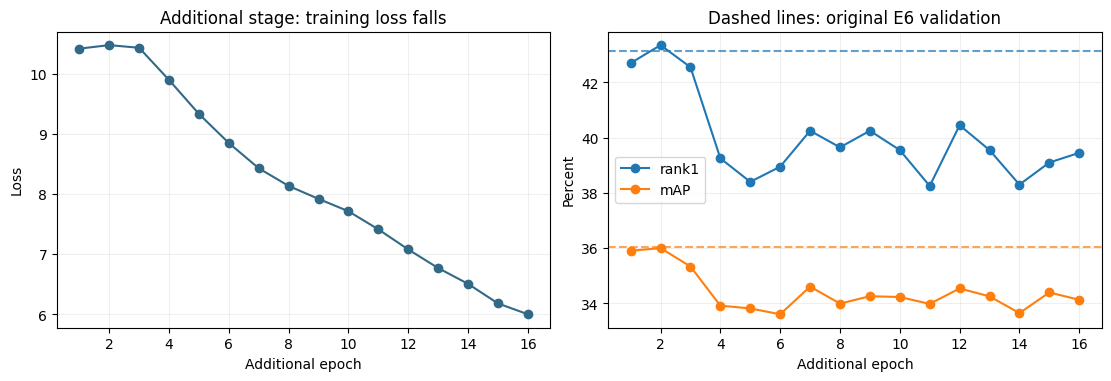

,epoch,total_loss,validation_rank1,validation_mAP
1,2,10.474,43.35,36.002
4,5,9.330,38.40,33.818
9,10,7.713,39.55,34.230
14,15,6.182,39.10,34.396
15,16,6.002,39.45,34.129


In [8]:
figure, axes = plt.subplots(1, 2, figsize=(11, 3.7), layout='constrained')
axes[0].plot(extra['epoch'], extra['total_loss'], marker='o', color='#326986')
axes[0].set(title='Additional stage: training loss falls', xlabel='Additional epoch', ylabel='Loss')
for field, baseline in (('validation_rank1', study['selected_model']['validation']['rank1']), ('validation_mAP', study['selected_model']['validation']['mAP'])):
    line = axes[1].plot(extra['epoch'], extra[field], marker='o', label=field.replace('validation_', ''))[0]
    axes[1].axhline(baseline, linestyle='--', color=line.get_color(), alpha=0.7)
axes[1].set(title='Dashed lines: original E6 validation', xlabel='Additional epoch', ylabel='Percent')
axes[1].legend()
for axis in axes:
    axis.grid(alpha=0.2)
plt.show()
display(extra.loc[extra['epoch'].isin([2, 5, 10, 15, 16]), ['epoch', 'total_loss', 'validation_rank1', 'validation_mAP']].round(3))

## 9. Different details, different images
The following are screenshots of genuine model-ranked searches captured from the project's earlier research interface. They illustrate the idea; no website code, deployment, or live application is included here. The recorded prompts, gallery indices, and cosine scores are in `research/illustrated-searches.json`.

Pink coat, black leggings, and a yellow bicycle


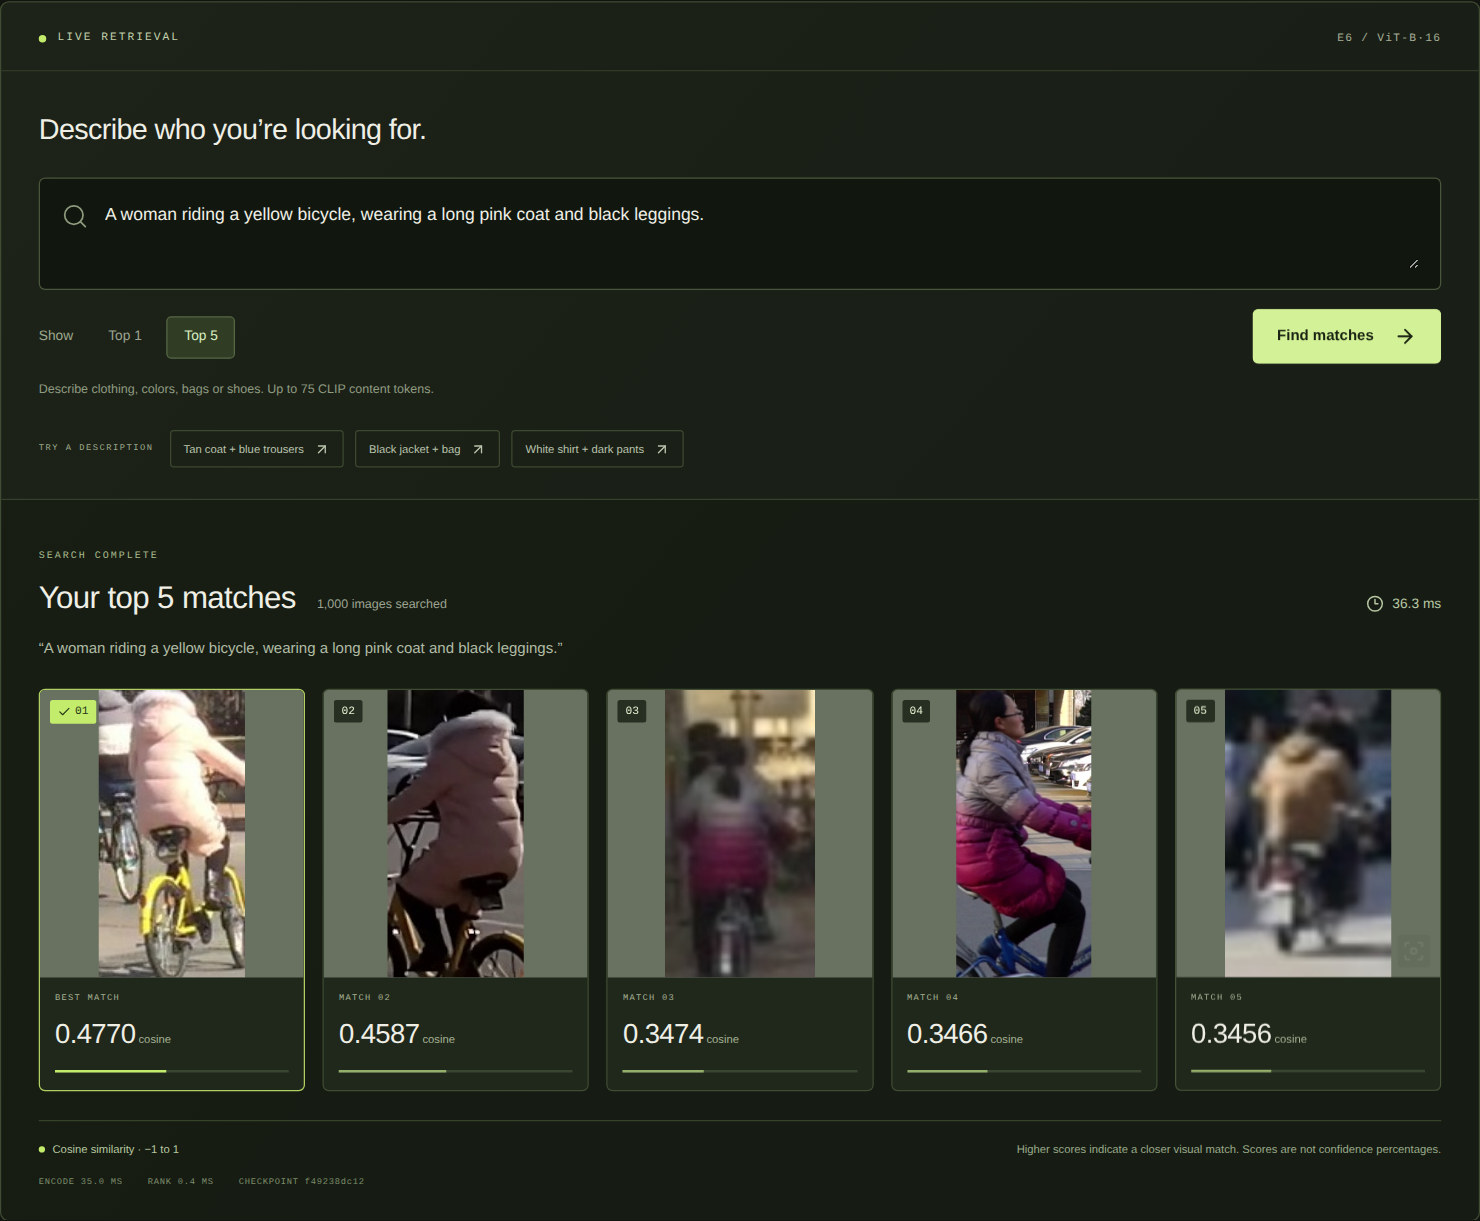

Patterned coat and a red bag


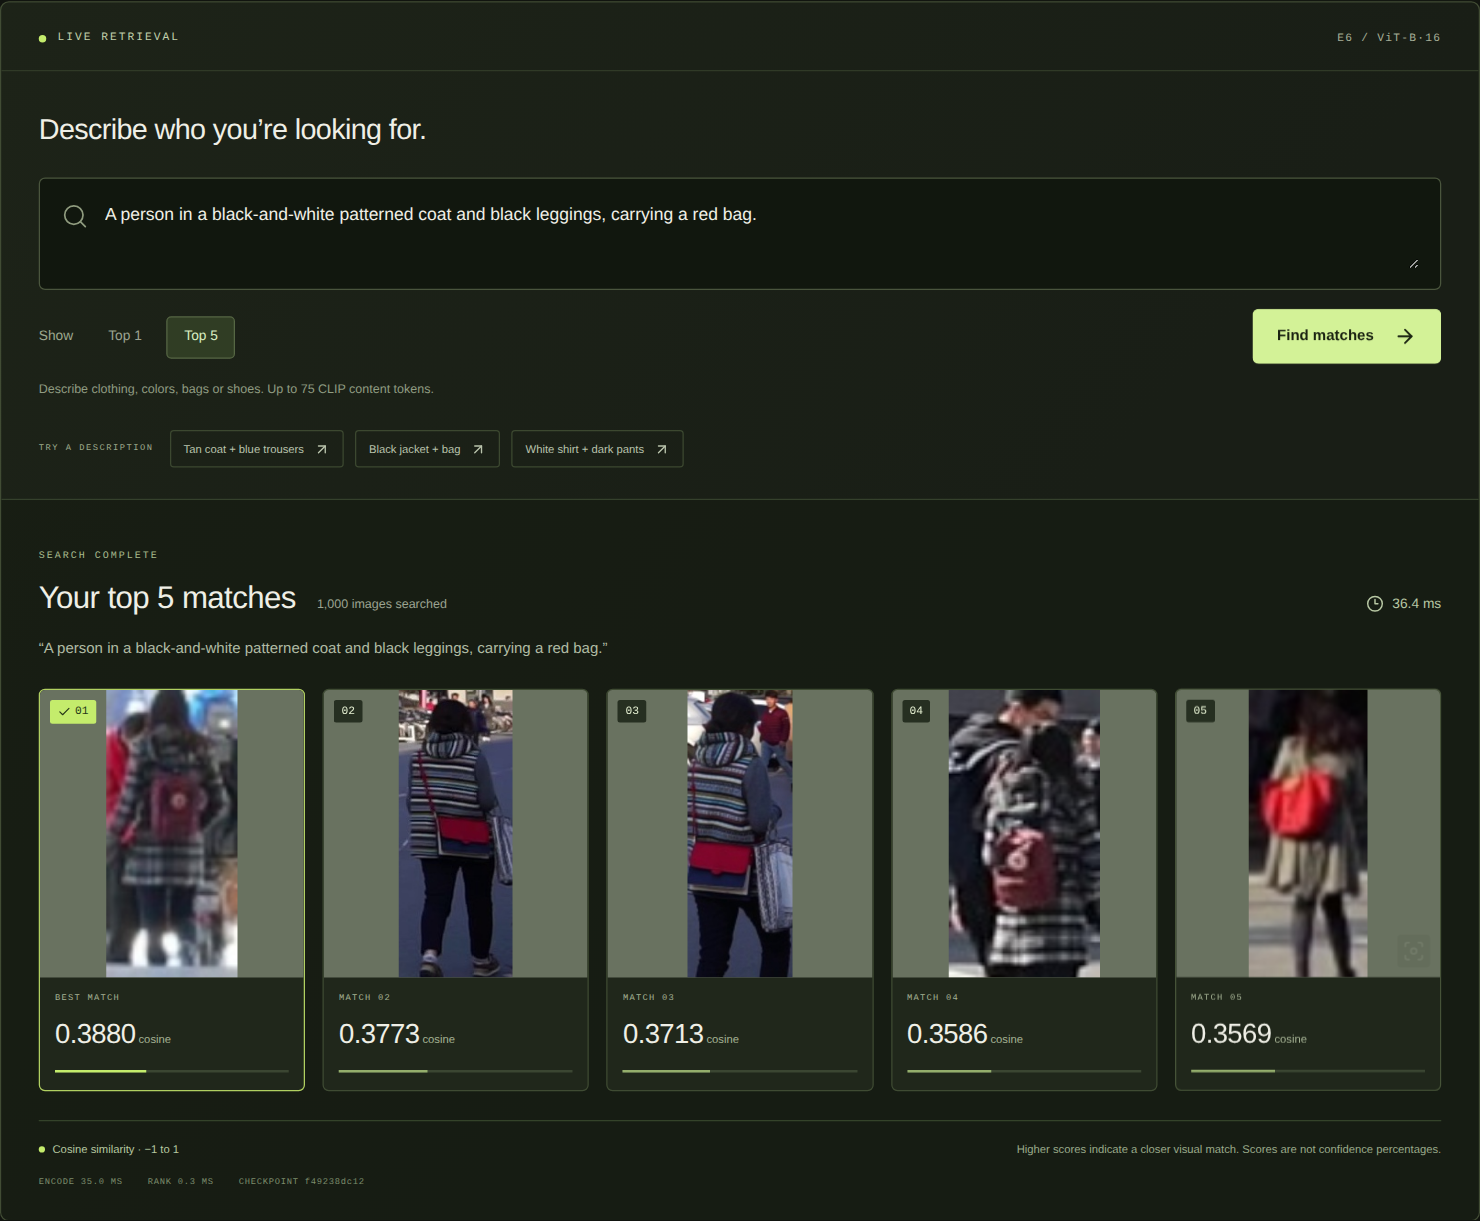

Striped sweater and a coat held in one hand


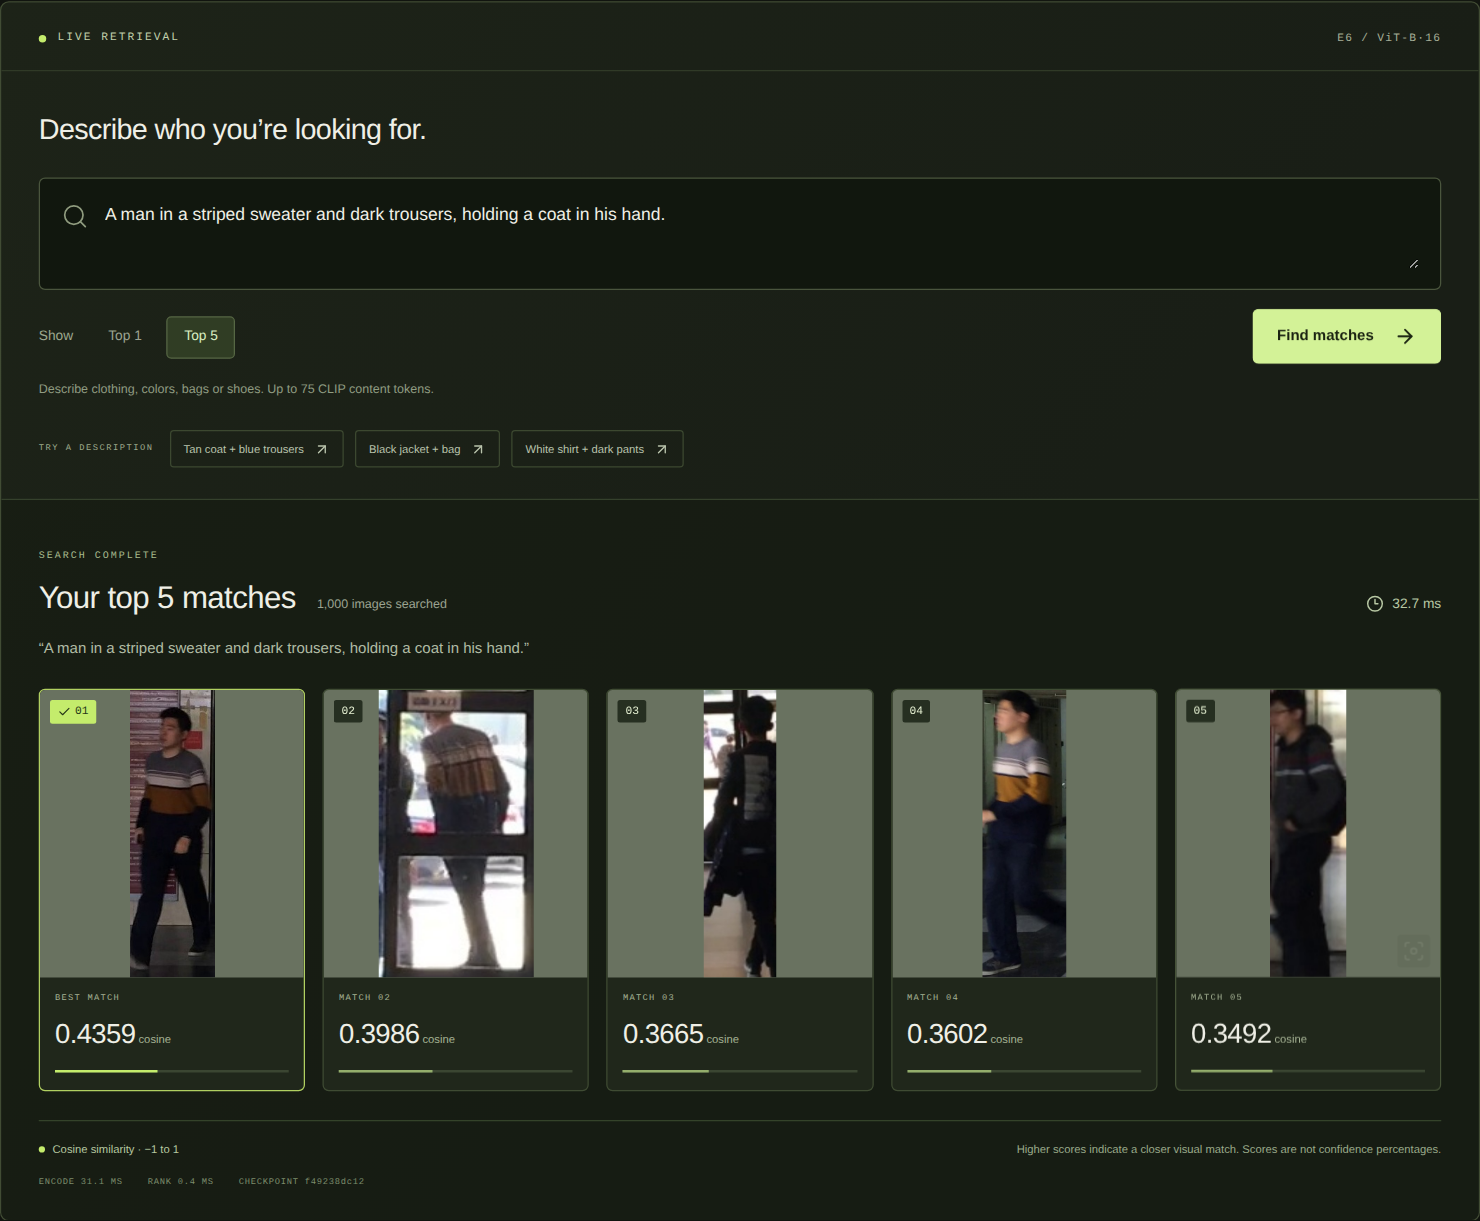

In [9]:
for filename, description in (
    ('search-pink-coat-bicycle.png', 'Pink coat, black leggings, and a yellow bicycle'),
    ('search-patterned-coat-red-bag.png', 'Patterned coat and a red bag'),
    ('search-striped-sweater.png', 'Striped sweater and a coat held in one hand'),
):
    print(description)
    display(Image(filename=str(ROOT / 'assets' / filename), width=1000))

## 10. What this project establishes
- A complete research pipeline connects descriptions to person images using pretrained CLIP and three learning signals.
- E6 reaches useful preliminary validation performance, with an explicit duplicate-image quarantine and reproducible settings.
- Additional fine-tuning lowered training loss without clear overall retrieval gains. More training alone was insufficient under this schedule.
- Similar outfits, missing details, and captions shared across identities remain difficult. Appearance similarity is not real-world identity verification.

A matched full-data random-masking baseline, repeated seeds, and frozen held-out test evaluation are still needed. Partial fine-tuning or smaller learning rates are possible future experiments, not proven improvements.

**References:** [IRRA, CVPR 2023](https://arxiv.org/abs/2303.12501) · [KPDM, AAAI 2026](https://ojs.aaai.org/index.php/AAAI/article/view/38199) · [Data Efficient MLM, EMNLP 2021](https://aclanthology.org/2021.findings-emnlp.259/) · [RSTPReid](https://github.com/NjtechCVLab/RSTPReid-Dataset). Implementation provenance and attribution are included in the repository.